# YOLO11s-seg · detección y segmentación de peces (AutoFish → clase única `fish`)

Entrenamiento de **YOLO11s-seg** en **Google Colab (GPU L4)** sobre el dataset [`vapaau/autofish`](https://huggingface.co/datasets/vapaau/autofish) (1 500 imágenes, 25 grupos × 60 imágenes, ~18 000 máscaras de instancia de peces sobre bandejas, con distintos niveles de solapamiento).

**Objetivo:** que el modelo aprenda a reconocer *peces en general* y a **contarlos/segmentarlos** cuando están distribuidos en bandejas. Por eso las 7 especies del dataset se fusionan en una sola clase: `fish`.

## Split (por grupo, sin fuga de datos)
| Split | Grupos | Imágenes |
|---|---|---|
| train | 1 – 20 | 1 200 |
| val | 21 – 22 | 120 |
| test | 23 – 25 | 180 |

Cada pez aparece en **un solo grupo**, así que separar por grupo garantiza que val/test contienen peces que el modelo nunca vio (si se separara por imagen, el mismo pez en otra pose estaría en train y test y la métrica sería optimista).

## Streaming del dataset
Las imágenes son PNG de ~7 MB (2464×2056; 15.9 GB en total). En lugar de clonar el repo:
1. Se descarga solo `annotations.json` (COCO, 12 MB).
2. Cada imagen se **descarga a memoria por HTTP, se redimensiona** a `IMGSZ` y se guarda como JPEG (~200 KB). Nunca se escribe el PNG original en disco → ~0.3 GB en vez de 16 GB, y se hace en paralelo con hilos.
3. Los polígonos se convierten a formato YOLO-seg con `category_id → 0`.

## Medidas para aprovechar el hardware (L4 24 GB)
- **AMP (fp16)** en el entrenamiento (tensor cores de la L4).
- **`cache='ram'`**: las imágenes ya redimensionadas (~3 GB) quedan decodificadas en RAM → la CPU de Colab (pocos núcleos) no es el cuello de botella del dataloader.
- **Redimensionado previo** a `IMGSZ`: evita decodificar PNG de 5 Mpx en cada época.
- `workers` ajustado a los núcleos disponibles, `batch=16` a 1024 px (con `nbs=64` Ultralytics acumula gradiente hasta un batch efectivo de 64).
- Descarga paralela con `ThreadPoolExecutor`, reanudable (omite imágenes ya presentes).
- Resultados opcionalmente en Google Drive (`SAVE_TO_DRIVE`) y `resume` si Colab se desconecta.

## Medidas de regularización / generalización
El dataset es pequeño y **muy redundante** (cada pez aparece en ~20 fotos casi idénticas), con una sola clase y fondo (cinta/bandeja) siempre igual. El riesgo principal es memorizar fondo y poses. Medidas:

**Aumentación (con una sola clase, el peso recae en la variedad visual):**
- *Mosaic* (4 imágenes en una → distintos conteos, escalas y contextos) y *close_mosaic* en las últimas épocas para ajustar a la distribución real.
- *MixUp* y **Copy-Paste** (específico de segmentación: pega peces con su máscara en otras imágenes, creando nuevos solapamientos y densidades).
- Geométricas: flips horizontal **y vertical** (la vista cenital no tiene "arriba"), rotación, escala (±50 %), traslación, cizalla y perspectiva leves.
- Color: HSV (tono, saturación, brillo) para robustez a iluminación/color de bandeja.
- *Random Erasing* (oclusiones) y, si `albumentations` está instalado, Blur/MedianBlur/CLAHE/ToGray automáticos de Ultralytics.

**Optimización / regularización explícita:**
- Partir de pesos **preentrenados COCO** (transfer learning).
- **AdamW** con `weight_decay` aumentado (1e-3) y **LR coseno** (`cos_lr`) con *warmup*.
- **Early stopping** (`patience`) sobre la métrica de val; se conserva `best.pt`.
- **EMA** de pesos (activo por defecto en Ultralytics) para suavizar el modelo final.
- Split por **grupo** y val independiente del test (el test solo se usa al final; el umbral de confianza se elige en val).
- `seed` fija para reproducibilidad.

## Análisis del conjunto de test (al final del notebook)
1. Métricas Ultralytics (box y máscara) en train / val / test → **brecha de generalización**.
2. Curvas PR, F1-confianza y matriz de confusión; umbral de confianza óptimo elegido **en val** (no en test).
3. **Conteo**: pez predicho vs. real por imagen (MAE, sesgo, scatter), por grupo y por nivel de ocupación de la bandeja.
4. Precisión/recall por **tamaño** de pez y por **densidad**, con emparejamiento IoU ≥ 0.5.
5. Galería de predicciones y de los **peores casos** (más FN/FP).

## 1 · Entorno

In [ ]:
!pip -q install -U ultralytics huggingface_hub
import torch, os, multiprocessing
print('torch', torch.__version__, '| CUDA', torch.cuda.is_available())
!nvidia-smi --query-gpu=name,memory.total --format=csv
print('CPUs:', multiprocessing.cpu_count())

torch 2.14.1+cu130 | CUDA True
name, memory.total [MiB]
NVIDIA L4, 23034 MiB
CPUs: 12


## 2 · Configuración

In [ ]:
import os
# ── Token de Hugging Face (descomenta y pega el tuyo) ───────────────────────
os.environ["HF_TOKEN"] = ""  # <--- Pega tu token de Hugging Face aquí
HF_TOKEN = os.environ.get("HF_TOKEN")   # None si no se define (el dataset es público)

REPO       = "vapaau/autofish"
DATA_ROOT  = "/content/autofish_yolo"
IMGSZ      = 1024            # tamaño de entrenamiento y de redimensionado previo
TRAIN_GROUPS = range(1, 21)  # 1-20
VAL_GROUPS   = range(21, 23) # 21-22
TEST_GROUPS  = range(23, 26) # 23-25

# Guardar resultados en Google Drive (recomendado para no perder el entrenamiento)
SAVE_TO_DRIVE = True
PROJECT = "/content/runs"
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT = "/content/drive/MyDrive/autofish_runs"
RUN_NAME = "yolo11s_seg_fish"
SEED = 0

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 3 · Streaming del dataset → formato YOLO-seg
`annotations.json` es formato COCO (`images` incluye el campo `group`). Los peces con varios polígonos (parcialmente ocluidos) se unen en un único polígono con `merge_multi_segment` de Ultralytics, igual que el conversor COCO oficial.

In [ ]:
import json, io, time, requests, numpy as np
from pathlib import Path
from PIL import Image
from concurrent.futures import ThreadPoolExecutor, as_completed
from tqdm.auto import tqdm
from ultralytics.data.converter import merge_multi_segment

root = Path(DATA_ROOT)
HEAD = {"Authorization": f"Bearer {HF_TOKEN}"} if HF_TOKEN else {}
BASE = f"https://huggingface.co/datasets/{REPO}/resolve/main"

r = requests.get(f"{BASE}/annotations.json", headers=HEAD, timeout=120); r.raise_for_status()
coco = r.json()
print({k: len(v) for k, v in coco.items()})

def split_of(g):
    return "train" if g in TRAIN_GROUPS else "val" if g in VAL_GROUPS else "test" if g in TEST_GROUPS else None

anns = {}
for a in coco["annotations"]:
    anns.setdefault(a["image_id"], []).append(a)

for s in ("train", "val", "test"):
    (root/"images"/s).mkdir(parents=True, exist_ok=True)
    (root/"labels"/s).mkdir(parents=True, exist_ok=True)

def label_lines(img):
    W, H = img["width"], img["height"]
    out = []
    for a in anns.get(img["id"], []):
        segs = [np.array(p, dtype=np.float64).reshape(-1, 2) / [W, H] for p in a["segmentation"] if len(p) >= 6]
        if not segs: continue
        seg = segs[0] if len(segs) == 1 else np.concatenate(merge_multi_segment(segs), axis=0)
        seg = np.clip(seg, 0, 1)
        out.append("0 " + " ".join(f"{v:.5f}" for v in seg.reshape(-1)))   # clase única: fish
    return out

def process(img):
    g = img["group"]; s = split_of(g)
    stem = f"g{g:02d}_{Path(img['file_name']).stem}"
    ip, lp = root/"images"/s/f"{stem}.jpg", root/"labels"/s/f"{stem}.txt"
    if ip.exists() and lp.exists(): return s, "skip"
    for attempt in range(5):
        try:
            resp = requests.get(f"{BASE}/{img['file_name']}", headers=HEAD, timeout=120)
            resp.raise_for_status()
            im = Image.open(io.BytesIO(resp.content)).convert("RGB")   # el PNG nunca toca el disco
            break
        except Exception as e:
            time.sleep(2 * (attempt + 1))
    else:
        raise RuntimeError(f"fallo descargando {img['file_name']}")
    scale = IMGSZ / max(im.size)
    im = im.resize((round(im.width*scale), round(im.height*scale)), Image.LANCZOS)
    lp.write_text("\n".join(label_lines(img)))
    im.save(ip, quality=95)          # se guarda al final: si existe la imagen, la etiqueta también
    return s, "ok"

todo = [i for i in coco["images"] if split_of(i["group"])]
with ThreadPoolExecutor(16) as ex:
    futs = [ex.submit(process, i) for i in todo]
    for f in tqdm(as_completed(futs), total=len(futs), desc="streaming"):
        f.result()

yaml_text = f"path: {DATA_ROOT}\ntrain: images/train\nval: images/val\ntest: images/test\nnames:\n  0: fish\n"
(root/"data.yaml").write_text(yaml_text)
for s in ("train", "val", "test"):
    print(s, len(list((root/'images'/s).glob('*.jpg'))), "imágenes")
!du -sh {DATA_ROOT}

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
{'images': 1500, 'annotations': 18158, 'categories': 7}


streaming:   0%|          | 0/1500 [00:00<?, ?it/s]

train 1200 imágenes
val 120 imágenes
test 180 imágenes
646M	/content/autofish_yolo


## 4 · Exploración rápida del dataset resultante

        count  mean  std  min  25%   50%   75%   max
split                                               
test    180.0  11.3  5.0  7.0  7.0  11.0  14.0  23.0
train  1200.0  12.3  4.9  7.0  8.0  11.0  16.0  24.0
val     120.0  11.3  4.1  7.0  8.0   9.0  17.0  17.0


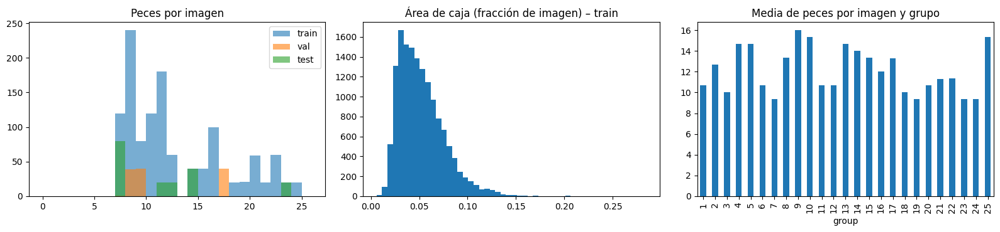

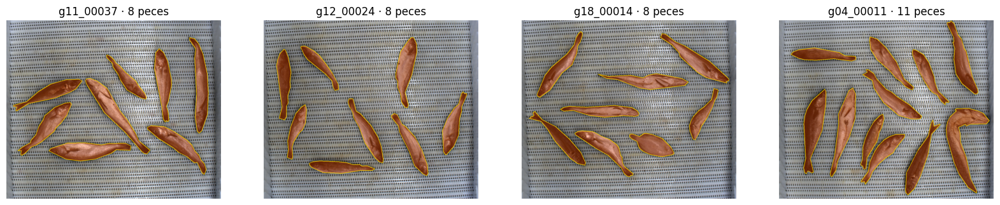

In [ ]:
import matplotlib.pyplot as plt, pandas as pd, cv2

def load_gt(split):
    # devuelve {stem: array (n,4) de cajas xyxy normalizadas}
    d = {}
    for lp in sorted((root/"labels"/split).glob("*.txt")):
        boxes = []
        for ln in lp.read_text().splitlines():
            v = np.array(ln.split()[1:], dtype=float).reshape(-1, 2)
            boxes.append([*v.min(0), *v.max(0)])
        d[lp.stem] = np.array(boxes).reshape(-1, 4)
    return d

GT = {s: load_gt(s) for s in ("train", "val", "test")}
rows = []
for s, d in GT.items():
    for k, b in d.items():
        rows.append(dict(split=s, img=k, group=int(k[1:3]), n=len(b)))
df_gt = pd.DataFrame(rows)
print(df_gt.groupby("split").n.describe().round(1))

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
for s in GT: ax[0].hist(df_gt[df_gt.split == s].n, bins=range(0, 27), alpha=.6, label=s)
ax[0].set_title("Peces por imagen"); ax[0].legend()
areas = np.concatenate([((b[:,2]-b[:,0])*(b[:,3]-b[:,1])) for b in GT["train"].values()])
ax[1].hist(areas, bins=50); ax[1].set_title("Área de caja (fracción de imagen) – train")
df_gt.groupby("group").n.mean().plot.bar(ax=ax[2], title="Media de peces por imagen y grupo")
plt.tight_layout(); plt.show()

def draw_gt(stem, split):
    im = cv2.cvtColor(cv2.imread(str(root/"images"/split/f"{stem}.jpg")), cv2.COLOR_BGR2RGB)
    h, w = im.shape[:2]; ov = im.copy()
    for ln in (root/"labels"/split/f"{stem}.txt").read_text().splitlines():
        pts = (np.array(ln.split()[1:], dtype=float).reshape(-1, 2) * [w, h]).astype(np.int32)
        cv2.fillPoly(ov, [pts], (255, 80, 0)); cv2.polylines(im, [pts], True, (255, 255, 0), 2)
    return cv2.addWeighted(ov, .35, im, .65, 0)
sample = df_gt[df_gt.split == "train"].sample(4, random_state=1)
fig, ax = plt.subplots(1, 4, figsize=(20, 4))
for a, (_, r_) in zip(ax, sample.iterrows()):
    a.imshow(draw_gt(r_.img, "train")); a.set_title(f"{r_.img} · {r_.n} peces"); a.axis("off")
plt.show()

## 5 · Entrenamiento
Hiperparámetros de aumentación y regularización comentados en el encabezado. Notas:
- `degrees=30` + flips H/V: la orientación de los peces en la bandeja es arbitraria. No se usa 180° porque rotaciones grandes inflan las cajas derivadas de los polígonos.
- `copy_paste` solo afecta a modelos de segmentación (usa las máscaras).
- `close_mosaic=15`: las últimas 15 épocas sin mosaic/copy-paste para converger sobre imágenes "reales".
- Si Colab se desconecta: ejecuta la celda de **reanudar** en lugar de la de entrenar.

In [ ]:
from ultralytics import YOLO

model = YOLO("yolo11s-seg.pt")          # preentrenado en COCO
results = model.train(
    data=f"{DATA_ROOT}/data.yaml",
    project=PROJECT, name=RUN_NAME, exist_ok=True,
    # ── rendimiento ──
    epochs=100, imgsz=IMGSZ, batch=16, nbs=64,
    amp=True, cache="ram", workers=min(8, multiprocessing.cpu_count()),
    device=0, seed=SEED, deterministic=False, plots=True,
    # ── optimización / regularización ──
    optimizer="AdamW", lr0=1e-3, lrf=0.01, cos_lr=True, warmup_epochs=3,
    weight_decay=1e-3, patience=20, overlap_mask=True,
    # ── aumentación ──
    mosaic=1.0, close_mosaic=15, mixup=0.15, copy_paste=0.3, copy_paste_mode="flip",
    fliplr=0.5, flipud=0.5, degrees=30, translate=0.1, scale=0.5, shear=5.0, perspective=0.0005,
    hsv_h=0.02, hsv_s=0.7, hsv_v=0.4, erasing=0.4,
)

Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=15, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.3, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/autofish_yolo/data.yaml, degrees=30, deterministic=False, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.02, hsv_s=0.7, hsv_v=0.4, imgsz=1024, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.15, mode=train, model=yolo11s-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11s_seg_fish, nbs=64, nms=None, opset=None, opt

In [ ]:
# ── Reanudar tras una desconexión (ejecutar EN LUGAR de la celda anterior) ──
# model = YOLO(f"{PROJECT}/{RUN_NAME}/weights/last.pt")
# model.train(resume=True)

## 6 · Curvas de entrenamiento

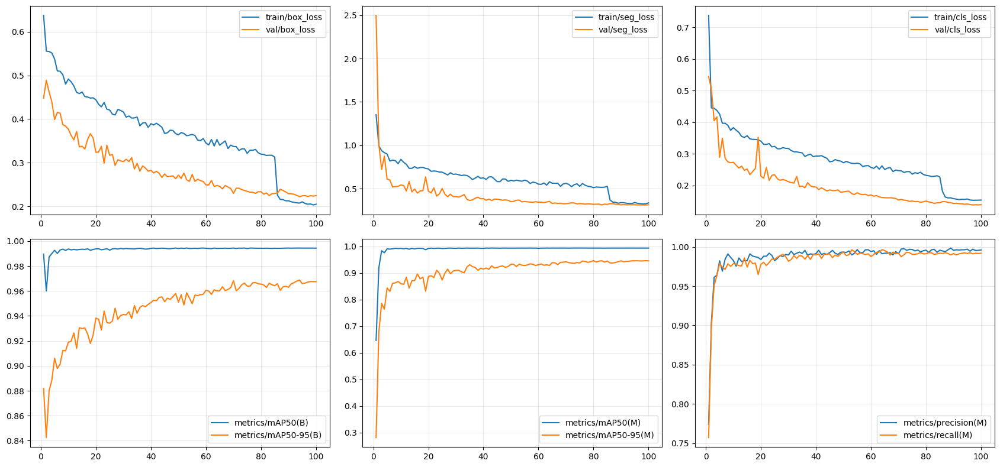

Mejor época (val, mAP50-95 máscara): 80  → 0.9465


In [ ]:
RUN = Path(PROJECT)/RUN_NAME
res = pd.read_csv(RUN/"results.csv"); res.columns = [c.strip() for c in res.columns]
fig, ax = plt.subplots(2, 3, figsize=(17, 8)); ax = ax.ravel()
pairs = [("train/box_loss", "val/box_loss"), ("train/seg_loss", "val/seg_loss"), ("train/cls_loss", "val/cls_loss"),
         ("metrics/mAP50(B)", "metrics/mAP50-95(B)"), ("metrics/mAP50(M)", "metrics/mAP50-95(M)"),
         ("metrics/precision(M)", "metrics/recall(M)")]
for a, p in zip(ax, pairs):
    for c in p: a.plot(res["epoch"], res[c], label=c)
    a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()
best = res.loc[res["metrics/mAP50-95(M)"].idxmax()]
print(f"Mejor época (val, mAP50-95 máscara): {int(best.epoch)}  → {best['metrics/mAP50-95(M)']:.4f}")

## 7 · Evaluación en train / val / test
Se compara el mismo modelo (`best.pt`) en los tres splits. Una brecha grande train→test indica sobreajuste; val→test indica que la selección de `best.pt` quedó ajustada a val.

In [ ]:
best_pt = RUN/"weights"/"best.pt"
model = YOLO(best_pt)
rows = {}
for s in ("train", "val", "test"):
    m = model.val(data=f"{DATA_ROOT}/data.yaml", split=s, imgsz=IMGSZ, batch=16, plots=(s == "test"),
                  project=PROJECT, name=f"eval_{s}", exist_ok=True, verbose=False)
    rows[s] = {"P(B)": m.box.mp, "R(B)": m.box.mr, "mAP50(B)": m.box.map50, "mAP50-95(B)": m.box.map,
               "P(M)": m.seg.mp, "R(M)": m.seg.mr, "mAP50(M)": m.seg.map50, "mAP50-95(M)": m.seg.map}
summary = pd.DataFrame(rows).T.round(4)
display(summary)
print("Brecha val→test mAP50-95(M):", round(summary.loc['val','mAP50-95(M)'] - summary.loc['test','mAP50-95(M)'], 4))
print("Brecha train→test mAP50-95(M):", round(summary.loc['train','mAP50-95(M)'] - summary.loc['test','mAP50-95(M)'], 4))

Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
YOLO11s-seg summary (fused): 113 layers, 10,067,203 parameters, 0 gradients, 32.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3113.8±956.9 MB/s, size: 439.1 KB)
val: Scanning /content/autofish_yolo/labels/train.cache... 1200 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1200/1200 314.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 75/75 3.2it/s 23.4s
                   all       1200      14759      0.994      0.994      0.994      0.982      0.995      0.995      0.993      0.966
Speed: 1.5ms preprocess, 13.3ms inference, 0.0ms loss, 1.2ms postprocess per image
Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
YOLO11s-seg summary (fused): 113 layers, 10,067,203 parameters, 0 gradients, 32.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0

,P(B),R(B),mAP50(B),mAP50-95(B),P(M),R(M),mAP50(M),mAP50-95(M)
train,0.9943,0.9944,0.9938,0.9815,0.9948,0.9953,0.9935,0.9656
val,0.9952,0.9919,0.9944,0.9697,0.9963,0.9925,0.9938,0.9446
test,0.9888,0.9920,0.9904,0.9597,0.9888,0.9920,0.9900,0.9281


Brecha val→test mAP50-95(M): 0.0165
Brecha train→test mAP50-95(M): 0.0375


### 7.1 · Curvas PR / F1 y matriz de confusión (test)

BoxPR_curve.png


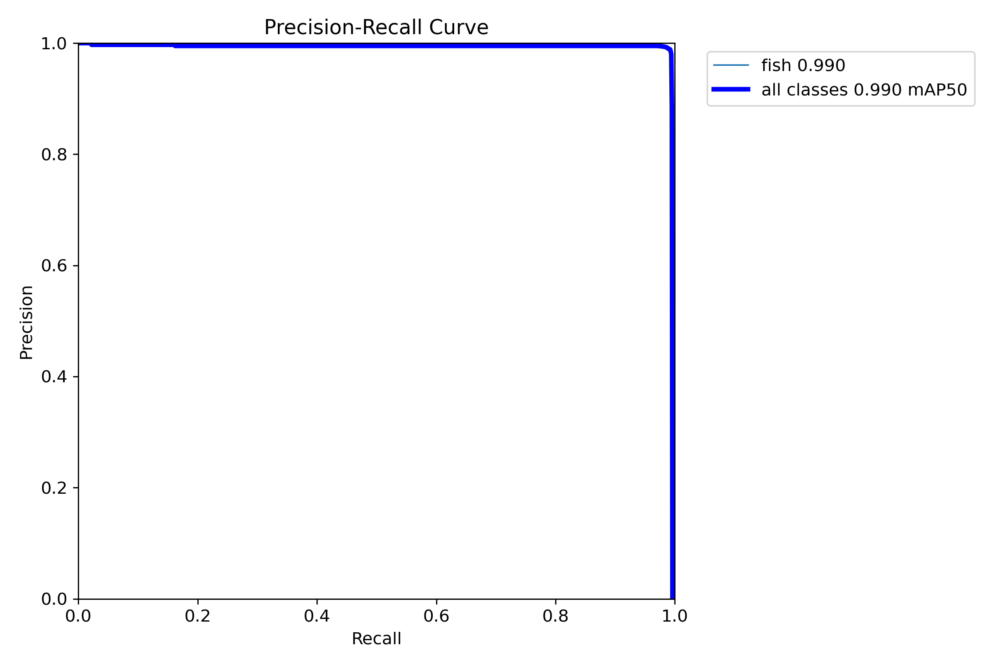

MaskPR_curve.png


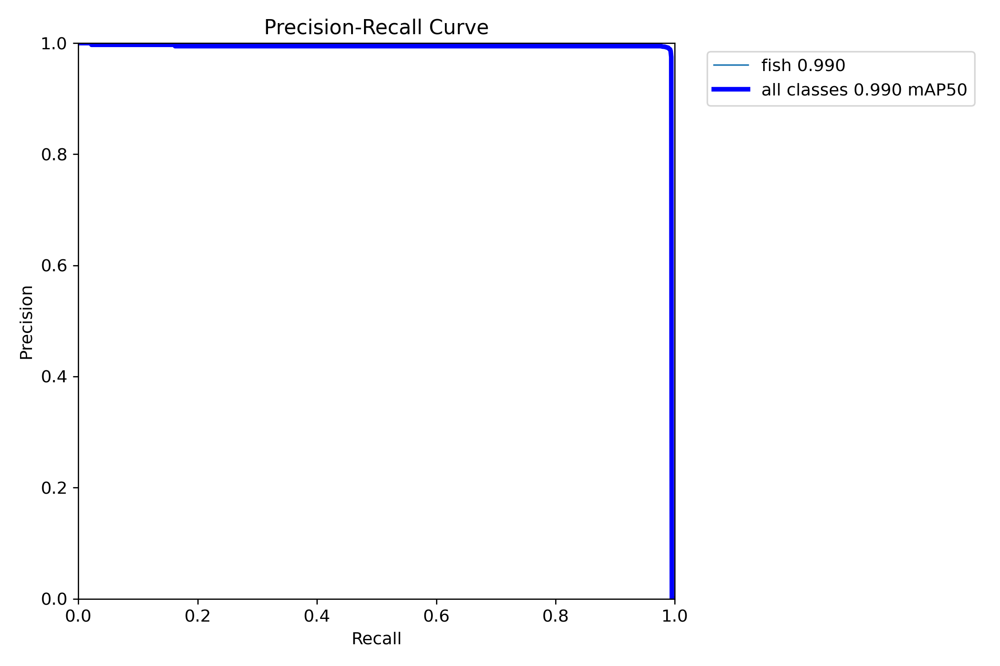

MaskF1_curve.png


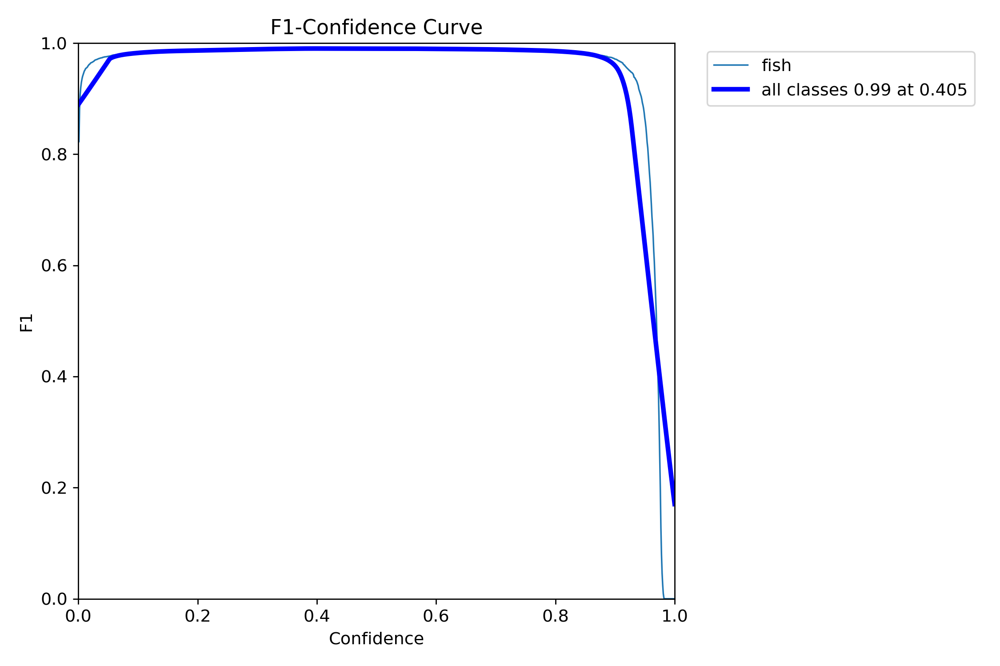

confusion_matrix.png


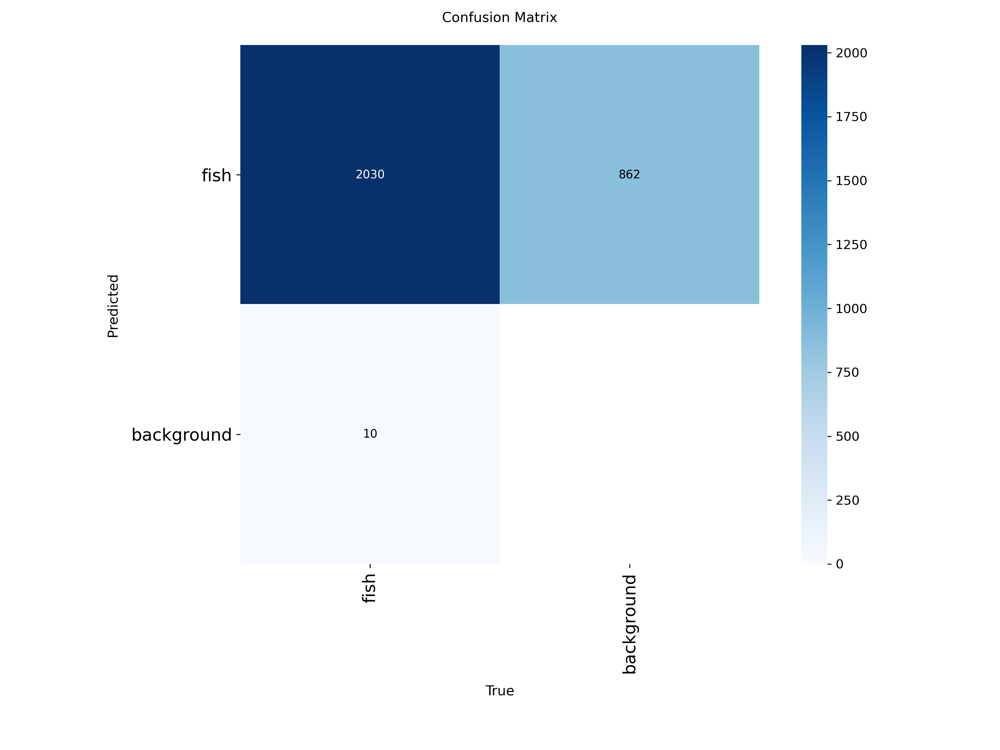

In [ ]:
from IPython.display import Image as IPImage, display
for f in ("BoxPR_curve.png", "MaskPR_curve.png", "MaskF1_curve.png", "confusion_matrix.png"):
    p = Path(PROJECT)/"eval_test"/f
    if p.exists(): print(f); display(IPImage(str(p), width=550))

## 8 · Análisis de test por imagen: conteo, tamaño y densidad
1. Se elige el **umbral de confianza óptimo sobre val** (máx. F1 con emparejamiento IoU≥0.5), para no ajustar el umbral con el test.
2. Se predice sobre test con ese umbral y se empareja cada predicción con el GT (greedy por confianza, IoU de cajas ≥ 0.5).

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


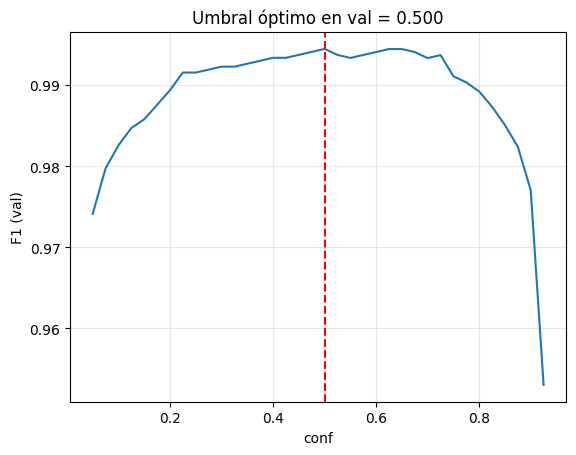

In [ ]:
def iou_matrix(a, b):
    if len(a) == 0 or len(b) == 0: return np.zeros((len(a), len(b)))
    x1 = np.maximum(a[:,None,0], b[None,:,0]); y1 = np.maximum(a[:,None,1], b[None,:,1])
    x2 = np.minimum(a[:,None,2], b[None,:,2]); y2 = np.minimum(a[:,None,3], b[None,:,3])
    inter = np.clip(x2-x1, 0, None) * np.clip(y2-y1, 0, None)
    aa = (a[:,2]-a[:,0])*(a[:,3]-a[:,1]); ab = (b[:,2]-b[:,0])*(b[:,3]-b[:,1])
    return inter / (aa[:,None] + ab[None] - inter + 1e-9)

def match(pred, conf, gt, thr=0.5):
    # greedy por confianza → (tp sobre pred, gt detectado)
    order = np.argsort(-conf); M = iou_matrix(pred[order], gt)
    tp = np.zeros(len(pred), bool); used = np.zeros(len(gt), bool)
    for i in range(len(order)):
        if M.shape[1] == 0: break
        j = np.where(~used, M[i], -1).argmax()
        if M[i, j] >= thr: tp[order[i]] = True; used[j] = True
    return tp, used

def predict_split(split, conf=0.05):
    files = sorted((root/"images"/split).glob("*.jpg"))
    out = {}
    for r_ in model.predict([str(f) for f in files], imgsz=IMGSZ, conf=conf, iou=0.6, max_det=100,
                            stream=True, verbose=False, half=True):
        h, w = r_.orig_shape
        b = r_.boxes.xyxy.cpu().numpy() / [w, h, w, h]
        out[Path(r_.path).stem] = (b, r_.boxes.conf.cpu().numpy())
    return out

PRED = {s: predict_split(s) for s in ("val", "test")}

# umbral óptimo en val
ths = np.arange(0.05, 0.95, 0.025); f1s = []
for t in ths:
    tp = fp = fn = 0
    for k, (b, c) in PRED["val"].items():
        keep = c >= t; ok, used = match(b[keep], c[keep], GT["val"][k])
        tp += ok.sum(); fp += (~ok).sum(); fn += (~used).sum()
    f1s.append(2*tp / (2*tp + fp + fn + 1e-9))
CONF = float(ths[int(np.argmax(f1s))])
plt.plot(ths, f1s); plt.axvline(CONF, c="r", ls="--"); plt.xlabel("conf"); plt.ylabel("F1 (val)"); plt.grid(alpha=.3)
plt.title(f"Umbral óptimo en val = {CONF:.3f}"); plt.show()

In [ ]:
# ── Tabla por imagen y por pez en test, con el umbral elegido en val ──
img_rows, fish_rows = [], []
for k, gt in GT["test"].items():
    b, c = PRED["test"][k]; keep = c >= CONF; b, c = b[keep], c[keep]
    tp, used = match(b, c, gt)
    img_rows.append(dict(img=k, group=int(k[1:3]), gt=len(gt), pred=len(b), tp=int(tp.sum()),
                         fp=int((~tp).sum()), fn=int((~used).sum())))
    for g, u in zip(gt, used):
        fish_rows.append(dict(img=k, group=int(k[1:3]), area=(g[2]-g[0])*(g[3]-g[1]), detected=bool(u)))
dfi, dff = pd.DataFrame(img_rows), pd.DataFrame(fish_rows)
dfi["err"] = dfi["pred"] - dfi["gt"]

TP, FP, FN = dfi.tp.sum(), dfi.fp.sum(), dfi.fn.sum()
print(f"Umbral conf={CONF:.3f} | Precisión={TP/(TP+FP):.4f}  Recall={TP/(TP+FN):.4f}  F1={2*TP/(2*TP+FP+FN):.4f}")
print(f"Conteo → MAE={dfi.err.abs().mean():.3f} peces/img | sesgo={dfi.err.mean():+.3f} | RMSE={np.sqrt((dfi.err**2).mean()):.3f} "
      f"| conteo exacto: {(dfi.err == 0).mean():.1%} | |err|<=1: {(dfi.err.abs() <= 1).mean():.1%}")

Umbral conf=0.500 | Precisión=0.9926  Recall=0.9868  F1=0.9897
Conteo → MAE=0.067 peces/img | sesgo=-0.067 | RMSE=0.380 | conteo exacto: 95.6% | |err|<=1: 98.9%


### 8.1 · Conteo predicho vs. real

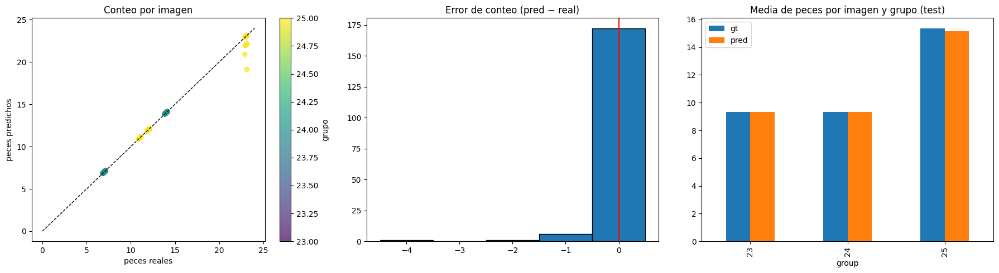

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
j = np.random.default_rng(0).uniform(-.15, .15, len(dfi))
sc = ax[0].scatter(dfi["gt"] + j, dfi["pred"] + j, c=dfi["group"], cmap="viridis", alpha=.7)
lim = [0, max(dfi["gt"].max(), dfi["pred"].max()) + 1]; ax[0].plot(lim, lim, "k--", lw=1)
ax[0].set_xlabel("peces reales"); ax[0].set_ylabel("peces predichos"); ax[0].set_title("Conteo por imagen"); plt.colorbar(sc, ax=ax[0], label="grupo")
ax[1].hist(dfi["err"], bins=np.arange(dfi["err"].min()-.5, dfi["err"].max()+1.5, 1), edgecolor="k")
ax[1].set_title("Error de conteo (pred − real)"); ax[1].axvline(0, c="r")
dfi.groupby("group")[["gt", "pred"]].mean().plot.bar(ax=ax[2], title="Media de peces por imagen y grupo (test)")
plt.tight_layout(); plt.show()

### 8.2 · Por densidad (nº de peces reales) y por grupo
Los grupos incluyen subconjuntos *Set1/Set2* (peces separados) y *All* (muchos peces con alto solape). El nº de peces reales por imagen sirve como proxy de la densidad/solape de la bandeja.

In [ ]:
dfi["densidad"] = pd.cut(dfi["gt"], [0, 8, 12, 16, 100], labels=["<=8", "9-12", "13-16", ">16"], include_lowest=True)

def agg(g):
    tp, fp, fn = g["tp"].sum(), g["fp"].sum(), g["fn"].sum()
    return pd.Series(dict(
        imgs=len(g),
        gt=g["gt"].sum(),
        precision=tp / (tp + fp + 1e-9),
        recall=tp / (tp + fn + 1e-9),
        f1=2 * tp / (2 * tp + fp + fn + 1e-9),
        MAE_conteo=g["err"].abs().mean(),
        sesgo=g["err"].mean()
    ))

print("— Por densidad —"); display(dfi.groupby("densidad", observed=True)[list(dfi.columns)].apply(agg).round(3))
print("— Por grupo —");    display(dfi.groupby("group")[list(dfi.columns)].apply(agg).round(3))

— Por densidad —


,imgs,gt,precision,recall,f1,MAE_conteo,sesgo
densidad,,,,,,,
<=8,80.0,560.0,1.000,1.000,1.000,0.0,0.0
9-12,40.0,460.0,0.978,0.978,0.978,0.0,0.0
13-16,40.0,560.0,1.000,1.000,1.000,0.0,0.0
>16,20.0,460.0,0.989,0.963,0.976,0.6,-0.6


— Por grupo —


,imgs,gt,precision,recall,f1,MAE_conteo,sesgo
group,,,,,,,
23,60.0,560.0,1.000,1.000,1.000,0.0,0.0
24,60.0,560.0,1.000,1.000,1.000,0.0,0.0
25,60.0,920.0,0.983,0.971,0.977,0.2,-0.2


### 8.3 · Recall por tamaño del pez

,peces,recall,area_media
tamaño,,,
XS,510,0.9804,0.0255
S,510,0.9863,0.0379
M,510,0.9863,0.0535
L,510,0.9941,0.0799


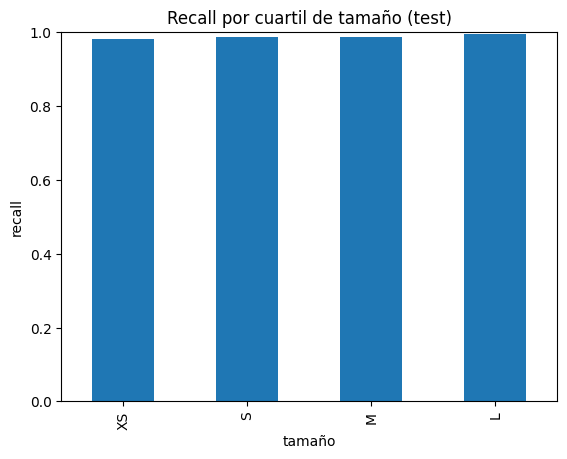

In [ ]:
dff["tamaño"] = pd.qcut(dff.area, 4, labels=["XS", "S", "M", "L"])
tab = dff.groupby("tamaño", observed=True).agg(peces=("detected", "size"), recall=("detected", "mean"),
                                                area_media=("area", "mean")).round(4)
display(tab); tab.recall.plot.bar(ylim=(0, 1), title="Recall por cuartil de tamaño (test)", ylabel="recall"); plt.show()

### 8.4 · Galería cualitativa
Verde = máscara predicha, recuadro rojo = pez real no detectado (FN). Primero casos al azar; después **los peores** por errores totales (FP+FN).

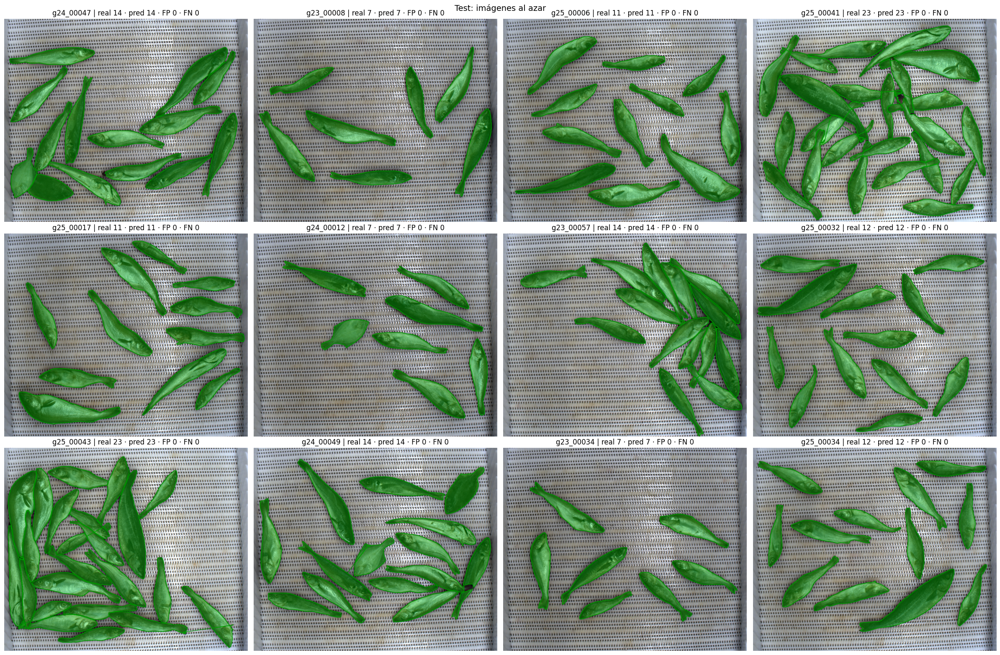

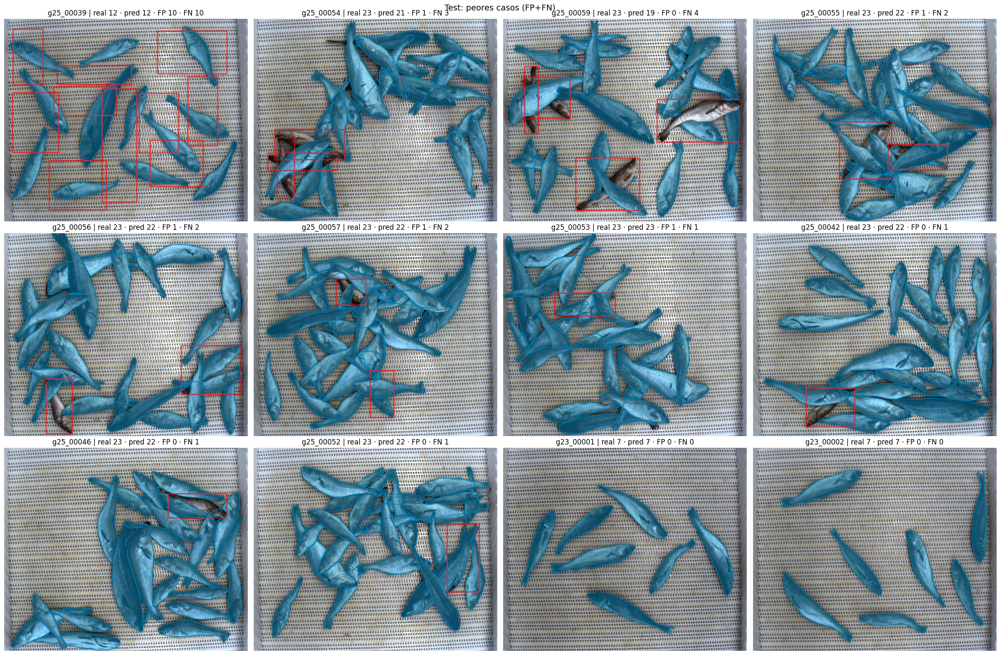

In [ ]:
def draw_pred(stem, split="test", color=(0, 220, 0)):
    f = root / "images" / split / f"{stem}.jpg"
    r_ = model.predict(str(f), imgsz=IMGSZ, conf=CONF, iou=0.6, verbose=False)[0]
    im = cv2.cvtColor(cv2.imread(str(f)), cv2.COLOR_BGR2RGB)
    h, w = im.shape[:2]
    ov = im.copy()

    # Borde un poco más oscuro que el relleno
    border_color = tuple(int(c * 0.55) for c in color)

    if r_.masks is not None:
        for poly in r_.masks.xy:
            pts = [poly.astype(np.int32)]
            cv2.fillPoly(ov, pts, color)
            cv2.polylines(im, pts, True, border_color, 2)

    b, c = PRED["test"][stem]
    keep = c >= CONF
    _, used = match(b[keep], c[keep], GT["test"][stem])
    for g, u in zip(GT["test"][stem], used):
        if not u:
            cv2.rectangle(im, (int(g[0]*w), int(g[1]*h)), (int(g[2]*w), int(g[3]*h)), (255, 0, 0), 4)

    return cv2.addWeighted(ov, .35, im, .65, 0)

def gallery(stems, title, color=(0, 220, 0)):
    fig, ax = plt.subplots(3, 4, figsize=(24, 16))
    axes = ax.ravel()
    for a, s in zip(axes, stems):
        row = dfi[dfi["img"] == s].iloc[0]
        a.imshow(draw_pred(s, color=color))
        a.axis("off")
        a.set_title(f"{s} | real {row['gt']} · pred {row['pred']} · FP {row['fp']} · FN {row['fn']}")

    # Oculta ejes sobrantes si hay menos de 12 imágenes
    for a in axes[len(stems):]:
        a.axis("off")

    plt.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()

# Ejemplos de uso:
gallery(dfi.sample(min(12, len(dfi)), random_state=0)["img"], "Test: imágenes al azar", color=(0, 220, 0))
gallery(dfi.assign(bad=dfi["fp"] + dfi["fn"]).nlargest(12, "bad")["img"], "Test: peores casos (FP+FN)", color=(0, 180, 255))

### 8.5 · Resumen y exportación
Guarda las tablas del análisis y (opcional) exporta el modelo a ONNX para inferencia fuera de Colab.

In [ ]:
out = Path(PROJECT)/"analisis_test"; out.mkdir(exist_ok=True, parents=True)
summary.to_csv(out/"metricas_splits.csv"); dfi.to_csv(out/"test_por_imagen.csv", index=False); dff.to_csv(out/"test_por_pez.csv", index=False)
print("Guardado en", out)
# model.export(format="onnx", imgsz=IMGSZ)   # opcional

Guardado en /content/drive/MyDrive/autofish_runs/analisis_test
